# 05 · NLP: modelos, validación, métricas e inferencia estadística

**Entradas** (`scripts/nlp_experiments.py`):

* `nlp_cv_scores.csv`: 5 semillas × 5 folds sobre desarrollo (train+val) por modelo, con todas las
  métricas. Se usa para la t remuestreada corregida (Nadeau–Bengio), Friedman + Holm y la varianza
  entre semillas.
* `nlp_test_preds.csv`: probabilidades en validación y en el **test sellado** (una evaluación por modelo
  final y semilla). Se usa para IC bootstrap, McNemar, calibración (H5) y umbral de decisión.

| Pos | Modelo | Implementación |
|---|---|---|
| 0 | Clase mayoritaria, TF-IDF + LR, NB-SVM | scikit-learn / propia (`models_text.NBSVM`) |
| 1 | DistilBERT / RoBERTa | `transformers` (`transformer_text.fine_tune`: warmup, LLRD, fp16, ≥ 5 semillas) |
| 2 | Word2Vec + BiLSTM | **propia en Keras** (`build_bilstm`: pooling último/max/atención, máscara) |
| 3 | CNN-1D (Kim, 2014) | **propia en Keras** (`build_cnn1d`) |
| 4 | TF-IDF + XGBoost | `xgboost` + Optuna, early stopping, calibración posterior |
| 5 | FastText supervisado | `fasttext` (n-gramas de palabra y carácter) |

Si no hay resultados reales, se usan los de `reports/demo` (baselines sobre el corpus sintético) para
validar el análisis. **Esas cifras no se reportan.**

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from project.calibration import expected_calibration_error, plot_reliability
from project.config import CFG, report_dirs, set_global_seed
from project.nlp_pipeline import classification_metrics
from project.stats import (bootstrap_ci, compare_models, corrected_resampled_ttest, fmt_ci, holm_adjust,
                           mcnemar_exact, plot_cd_diagram)

warnings.filterwarnings("ignore")
set_global_seed(CFG.seed)
ROOT = Path("..").resolve()
REAL = (ROOT / "reports/tables/nlp_cv_scores.csv").exists()
SRC = ROOT / ("reports/tables" if REAL else "reports/demo/tables")
TAB, FIG = report_dirs(ROOT, REAL)
PREREG = yaml.safe_load((ROOT / "configs/prereg.yaml").read_text())
DELTA = PREREG["efecto_minimo_relevante"]["nlp_F1"]
cv = pd.read_csv(SRC / "nlp_cv_scores.csv"); tp = pd.read_csv(SRC / "nlp_test_preds.csv")
print("Modo:", "REAL" if REAL else "DEMO — cifras no reportables", "| modelos:", cv.modelo.unique().tolist())

Modo: DEMO — cifras no reportables | modelos: ['Clase mayoritaria', 'TF-IDF + LR', 'NB-SVM']


## 1. Resultados en el test sellado: media [IC 95 %]

Las probabilidades se promedian entre semillas (ensamble de semillas) para el IC bootstrap sobre
ejemplos. La variabilidad entre semillas se reporta aparte. La latencia es la de inferencia por texto
en CPU.

In [2]:
test = tp[tp.split == "test"]
pcols = [c for c in tp.columns if c.startswith("p_") and c != "p_T_max"]
classes = np.array([c[2:] for c in pcols])
rows, per_seed = {}, []
for m, g in test.groupby("modelo"):
    P = g.groupby("idx")[pcols].mean(); y = g.groupby("idx").y.first().to_numpy()
    yi = np.searchsorted(classes, y); pred = P.to_numpy().argmax(1)
    rng = np.random.default_rng(0); bs = []
    for _ in range(2000):
        i = rng.integers(0, len(y), len(y)); bs.append(classification_metrics(y[i], P.to_numpy()[i], classes))
    bs = pd.DataFrame(bs); point = classification_metrics(y, P.to_numpy(), classes)
    rows[m] = {k: f"{point[k]:.3f} [{bs[k].quantile(.025):.3f}, {bs[k].quantile(.975):.3f}]"
               for k in ("accuracy", "precision_macro", "recall_macro", "f1_macro", "mcc", "roc_auc", "pr_auc", "ece", "brier", "log_loss")}
    rows[m]["latencia_ms"] = f"{g.latencia_ms_por_texto.median():.3f}"
    for s, h in g.groupby("semilla"):
        per_seed.append(dict(modelo=m, semilla=s, **classification_metrics(h.y.to_numpy(), h[pcols].to_numpy(), classes)))
res = pd.DataFrame(rows).T
ps = pd.DataFrame(per_seed)
res["F1_macro_entre_semillas (media ± DE)"] = ps.groupby("modelo").f1_macro.agg(lambda s: f"{s.mean():.3f} ± {s.std(ddof=1) if len(s) > 1 else 0:.3f}")
res.to_csv(TAB / "nlp_tabla_resultados.csv"); res

,accuracy,precision_macro,recall_macro,f1_macro,mcc,roc_auc,pr_auc,ece,brier,log_loss,latencia_ms,F1_macro_entre_semillas (media ± DE)
Clase mayoritaria,"0.367 [0.307, 0.433]","0.122 [0.102, 0.144]","0.333 [0.333, 0.333]","0.179 [0.157, 0.201]","0.000 [0.000, 0.000]","0.500 [0.500, 0.500]","0.333 [0.333, 0.333]","0.633 [0.567, 0.693]","1.265 [1.135, 1.386]","17.478 [15.679, 19.152]",0.012,0.179 ± 0.000
NB-SVM,"0.986 [0.972, 1.000]","0.987 [0.972, 1.000]","0.985 [0.968, 1.000]","0.986 [0.970, 1.000]","0.979 [0.958, 1.000]","1.000 [0.999, 1.000]","1.000 [0.999, 1.000]","0.015 [0.005, 0.029]","0.018 [0.004, 0.037]","0.029 [0.007, 0.060]",0.032,0.986 ± 0.000
TF-IDF + LR,"0.991 [0.977, 1.000]","0.991 [0.978, 1.000]","0.989 [0.974, 1.000]","0.990 [0.976, 1.000]","0.986 [0.965, 1.000]","1.000 [0.999, 1.000]","1.000 [0.999, 1.000]","0.058 [0.049, 0.071]","0.023 [0.013, 0.036]","0.076 [0.058, 0.097]",0.033,0.990 ± 0.000


## 2. Comparación con repeticiones: Friedman + Holm, t corregida, McNemar

Friedman p = 1.33e-09 (n = 25 repeticiones semilla×fold)


,A,B,dF1_cv,ic,t_NB,p_NB,p_mcnemar_test,p_NB_holm,p_mcnemar_holm
0,Clase mayoritaria,NB-SVM,-0.8035,"-0.803 [-0.806, -0.800]",-181.6316,0.000,0.0,0.000,0.0
1,Clase mayoritaria,TF-IDF + LR,-0.8080,"-0.808 [-0.811, -0.805]",-206.3894,0.000,0.0,0.000,0.0
2,NB-SVM,TF-IDF + LR,-0.0046,"-0.005 [-0.007, -0.002]",-1.2823,0.212,1.0,0.212,1.0


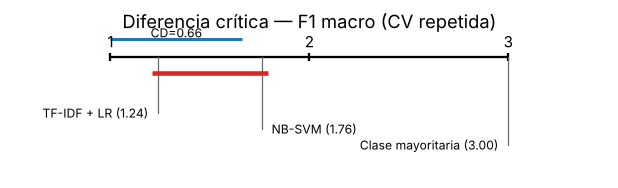

In [3]:
piv = cv.pivot_table(index=["semilla", "fold"], columns="modelo", values="f1_macro")
if piv.shape[1] >= 3:
    cm = compare_models(piv, delta=DELTA)
    print(f"Friedman p = {cm['friedman_p']:.2e} (n = {cm['n']} repeticiones semilla×fold)")
    plot_cd_diagram(cm["mean_ranks"], cm["cd_nemenyi"], title="Diferencia crítica — F1 macro (CV repetida)")
    plt.savefig(FIG / "nlp_cd.png", dpi=120, bbox_inches="tight")
# t remuestreada corregida y McNemar por pares (familia corregida con Holm)
n_tr, n_te = int(cv.n_train.mean()), int(cv.n_test.mean())
mods = list(piv.columns); pairs = []
P_test = {m: g.groupby("idx")[pcols].mean() for m, g in test.groupby("modelo")}
ytest = test.groupby("idx").y.first()
for i in range(len(mods)):
    for j in range(i + 1, len(mods)):
        a, b = mods[i], mods[j]
        d = (piv[a] - piv[b]).dropna()
        t, p = corrected_resampled_ttest(d.to_numpy(), n_tr, n_te)
        pa = classes[P_test[a].reindex(ytest.index).to_numpy().argmax(1)]; pb = classes[P_test[b].reindex(ytest.index).to_numpy().argmax(1)]
        pairs.append(dict(A=a, B=b, dF1_cv=d.mean(), ic=fmt_ci(*bootstrap_ci(d.to_numpy())), t_NB=t, p_NB=p,
                          p_mcnemar_test=mcnemar_exact(ytest.to_numpy(), pa, pb)))
pw = pd.DataFrame(pairs); pw["p_NB_holm"] = holm_adjust(pw.p_NB.to_numpy()); pw["p_mcnemar_holm"] = holm_adjust(pw.p_mcnemar_test.to_numpy())
pw.round(4)

### Contraste de H4 (hipótesis nula explícita)

Diferencia de F1 entre el mejor transformer y TF-IDF + XGBoost: t de Nadeau–Bengio con Holm, más
equivalencia práctica (TOST) con δ = 0.02.

In [4]:
tr_name = next((m for m in mods if any(k in m for k in ("BERT", "RoBERTa", "DistilBERT"))), None)
xgb = "TF-IDF + XGBoost" if "TF-IDF + XGBoost" in mods else None
if tr_name and xgb:
    d = (piv[tr_name] - piv[xgb]).dropna().to_numpy()
    k = len(d); se = np.sqrt((1 / k + n_te / n_tr) * d.var(ddof=1))
    from scipy import stats as sst
    lo, hi = d.mean() - sst.t.ppf(0.95, k - 1) * se, d.mean() + sst.t.ppf(0.95, k - 1) * se   # IC 90 % para TOST
    row = pw[((pw.A == tr_name) & (pw.B == xgb)) | ((pw.A == xgb) & (pw.B == tr_name))].iloc[0]
    verdict = ("REFUTADA (diferencia significativa y > δ)" if row.p_NB_holm < 0.05 and min(abs(lo), abs(hi)) > DELTA and np.sign(lo) == np.sign(hi)
               else "APOYADA (equivalencia práctica: IC 90 % ⊂ [−δ, δ])" if -DELTA < lo and hi < DELTA else "no concluyente")
    print(f"ΔF1 = {d.mean():.4f}; IC 90 % corregido [{lo:.4f}, {hi:.4f}]; p_Holm = {row.p_NB_holm:.4f} → H4 {verdict}")
else:
    print("H4 pendiente: requiere resultados de transformer y TF-IDF + XGBoost (`nlp_experiments.py cv --models all`).")

H4 pendiente: requiere resultados de transformer y TF-IDF + XGBoost (`nlp_experiments.py cv --models all`).


## 3. Calibración (H5) y umbral de decisión

* ECE, Brier y diagramas de confiabilidad antes y después de temperature scaling, ajustado **solo en
  validación**.
* Exactitud idéntica por construcción (fundamento 5), lo que se verifica abajo.
* Si los costos son asimétricos (por ejemplo, descartar a un candidato idóneo cuesta más que entrevistar
  a uno no idóneo), la política de decisión se fija con la curva de costo en validación.

,modelo,T,ECE_T1,ECE_T,dECE_ic,exactitud_igual
0,Clase mayoritaria,10.0000,0.6326,0.5205,"[0.1121, 0.1121]",True
1,NB-SVM,1.6922,0.0154,0.0125,"[-0.0022, 0.0066]",True
2,TF-IDF + LR,0.3799,0.0584,0.0103,"[0.0433, 0.0538]",True


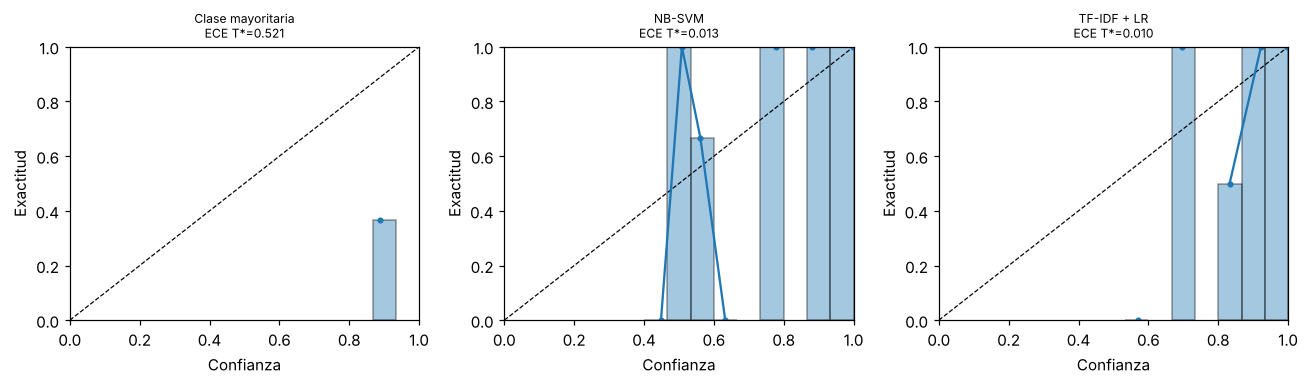

In [5]:
pT = [c for c in tp.columns if c.startswith("pT_")]
cal = []
fig, ax = plt.subplots(1, min(4, test.modelo.nunique()), figsize=(4 * min(4, test.modelo.nunique()), 3.6), squeeze=False)
for a, (m, g) in zip(ax[0], test.groupby("modelo")):
    yi = np.searchsorted(classes, g.y)
    P1, PT = g[pcols].to_numpy(), g[pT].to_numpy()
    assert (P1.argmax(1) == PT.argmax(1)).all()
    e1 = np.array([expected_calibration_error(P1[i], yi[i]) for i in [np.random.default_rng(s).integers(0, len(yi), len(yi)) for s in range(300)]])
    eT = np.array([expected_calibration_error(PT[i], yi[i]) for i in [np.random.default_rng(s).integers(0, len(yi), len(yi)) for s in range(300)]])
    cal.append(dict(modelo=m, T=g.temperatura.mean(), ECE_T1=expected_calibration_error(P1, yi), ECE_T=expected_calibration_error(PT, yi),
                    dECE_ic=f"[{np.percentile(e1 - eT, 2.5):.4f}, {np.percentile(e1 - eT, 97.5):.4f}]",
                    exactitud_igual=True))
    plot_reliability(PT, yi, ax=a); a.set_title(f"{m}\nECE T*={expected_calibration_error(PT, yi):.3f}", fontsize=8)
plt.tight_layout()
cal = pd.DataFrame(cal); cal.round(4)

In [6]:
if tr_name:
    base = cal.set_index("modelo")
    lr = "TF-IDF + LR"
    print("H5 (parte 1) ECE transformer T=1 vs TF-IDF+LR:", round(base.loc[tr_name, "ECE_T1"] - base.loc[lr, "ECE_T1"], 4))
    print("H5 (parte 2) reducción relativa de ECE con T*:", round(1 - base.loc[tr_name, "ECE_T"] / base.loc[tr_name, "ECE_T1"], 3))
else:
    print("H5 pendiente: requiere el transformer ajustado (las cifras de baselines arriba validan el procedimiento).")

H5 pendiente: requiere el transformer ajustado (las cifras de baselines arriba validan el procedimiento).


## 4. Matriz de confusión normalizada del mejor modelo y curva de aprendizaje

Pendiente: `nlp_experiments.py fractions`.


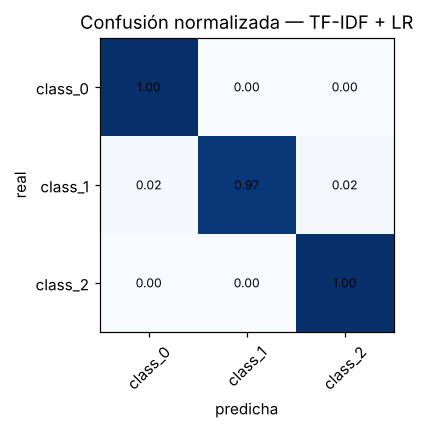

In [7]:
from sklearn.metrics import confusion_matrix
best = cv.groupby("modelo").f1_macro.mean().idxmax()
g = test[test.modelo == best].groupby("idx")
yb = g.y.first().to_numpy(); pb = classes[g[pcols].mean().to_numpy().argmax(1)]
C = confusion_matrix(yb, pb, labels=classes, normalize="true")
fig, ax = plt.subplots(figsize=(4.5, 4)); im = ax.imshow(C, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes, rotation=45); ax.set_yticks(range(len(classes))); ax.set_yticklabels(classes)
for i in range(len(classes)):
    for j in range(len(classes)): ax.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set(title=f"Confusión normalizada — {best}", xlabel="predicha", ylabel="real"); plt.tight_layout()
FR = SRC / "nlp_fractions.csv"
if FR.exists():
    fr = pd.read_csv(FR)
    fr.groupby(["fraccion", "modelo"]).f1_macro.mean().unstack().plot(marker="o", title="Curva de aprendizaje (F1 macro)", logx=True)
else:
    print("Pendiente: `nlp_experiments.py fractions`.")

## 5. Varianza: semilla vs split (Bouthillier et al., 2021) y ablación de preprocesamiento por familia

In [8]:
from project.stats import variance_decomposition
vd = pd.DataFrame({m: variance_decomposition(g.rename(columns={"f1_macro": "score", "fold": "split"}), "score", ("semilla", "split"))
                   for m, g in cv.groupby("modelo")}).T
print(vd.round(6))
PP = SRC / "nlp_preprocess.csv"
if PP.exists():
    pp = pd.read_csv(PP)
    print(pp.groupby(["modelo", "preprocesamiento"]).f1_macro.agg(["mean", "std"]).round(4))
    for m, g in pp.groupby("modelo"):
        pv = g.pivot_table(index=["semilla", "fold"], columns="preprocesamiento", values="f1_macro")
        if pv.shape[1] == 3:
            print(m, compare_models(pv)["pairwise"][["A", "B", "mean_diff", "p_holm"]].round(4).to_string(index=False))
else:
    print("Pendiente: `nlp_experiments.py preprocess --models all`.")

                    semilla     split     total
Clase mayoritaria  0.000000  0.000000  0.000000
NB-SVM             0.000003  0.000009  0.000060
TF-IDF + LR        0.000001  0.000002  0.000047
Pendiente: `nlp_experiments.py preprocess --models all`.


## 6. HPO del BiLSTM: importancia de hiperparámetros, interacciones y dependencia parcial

La rejilla completa tiene 576 configuraciones. Se exploran 30 trials con TPE y poda, el mismo
presupuesto que XGBoost. La importancia se estima con fANOVA y la dependencia parcial con la media
marginal del objetivo por valor.

In [9]:
H = SRC / "nlp_hpo_Word2Vec__BiLSTM.csv"
if H.exists():
    h = pd.read_csv(H); pc = [c for c in h.columns if c.startswith("params_")]
    fig, ax = plt.subplots(2, 4, figsize=(14, 5.5))
    for a, c in zip(ax.ravel(), pc):
        h.groupby(c)["value"].agg(["mean", "sem"]).plot(y="mean", yerr="sem", ax=a, marker="o", legend=False); a.set_title(c[7:], fontsize=8)
    plt.tight_layout()
    print((SRC / "nlp_hpo_Word2Vec__BiLSTM_importance.json").read_text())
    if {"params_lstm_units", "params_learning_rate"} <= set(h.columns):
        print(h.pivot_table(index="params_lstm_units", columns="params_learning_rate", values="value").round(3))
else:
    print("Pendiente: `nlp_experiments.py hpo --model 'Word2Vec + BiLSTM' --trials 30`.")

Pendiente: `nlp_experiments.py hpo --model 'Word2Vec + BiLSTM' --trials 30`.
